<a href="https://colab.research.google.com/github/meredithcfarley/cs-74-crisis-detection/blob/main/02models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#there was a separate colab that cleaned all the data
#this notebook starts from the cleaned dataset (saved in drive)
# cell 1
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount('/content/drive')

df = pd.read_parquet("/content/drive/MyDrive/CS74/cleaned.parquet")
print(df.shape)

X = df[["clean_text", "word_count"]]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Mounted at /content/drive
(232012, 5)
Train: (185609, 2)  Test: (46403, 2)


In [2]:
#set up cross validation and scoring
# cell 2
from sklearn.model_selection import StratifiedKFold, cross_validate

#split into 5 folds each with balanced distrib of labels
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["recall", "precision", "f1", "roc_auc"]

def show_cv(name, results):
    print(name)
    for metric in scoring:
        scores = results["test_" + metric]
        print(f"  {metric:10s} {scores.mean():.3f}  (+/- {scores.std():.3f})")

import os, joblib

RESULTS_DIR = "/content/drive/MyDrive/CS74/cv_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

def run_or_load(name, model, X, y):
    path = f"{RESULTS_DIR}/{name}.joblib"
    if os.path.exists(path):
        print(f"Loaded saved results for {name}")
        return joblib.load(path)
    print(f"Running cross-validation for {name}...")
    results = cross_validate(model, X, y, cv=cv, scoring=scoring)
    joblib.dump(results, path)
    return results

In [3]:
#length only baseline - how well does the model classify when only using post length?
# cell 3
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

#make sure always runs in order, rescale word count, LR classifier,
length_model = Pipeline([("scale", StandardScaler()),("clf", LogisticRegression())])

#run process and returns score for each metric
#x train gives model only word count column
length_results = run_or_load("length_only", length_model, X_train[["word_count"]], y_train)

show_cv("Length-only baseline", length_results)

Loaded saved results for length_only
Length-only baseline
  recall     0.591  (+/- 0.003)
  precision  0.814  (+/- 0.001)
  f1         0.685  (+/- 0.002)
  roc_auc    0.815  (+/- 0.001)


Interpretation of these results: ROC-AUC 0.815 from just word count is strong, model can separate classes really well just based on length! Precision is 0.815, recall is 0.591 - when the model says crisis, it's usually right. but it misses about 40% of crisis posts - probably shorter ones. the + - values show that the results are very consistent across folds

In [4]:
#naive bayes on TF- IDF cell 4

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

#vectorizer turns post into numbers, vuilds vocab and gives each post a score for the term - high ifthe term is frequent in that post but rare across all posts
#n gram range of unigrams and bigrams
nb_model = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),("clf", MultinomialNB())])

nb_results = run_or_load("naive_bayes", nb_model, X_train["clean_text"], y_train)
show_cv("Naive Bayes (TF-IDF)", nb_results)

Loaded saved results for naive_bayes
Naive Bayes (TF-IDF)
  recall     0.935  (+/- 0.002)
  precision  0.884  (+/- 0.001)
  f1         0.909  (+/- 0.001)
  roc_auc    0.969  (+/- 0.001)


Interpretation: ROC-AUC of 0.989 shows that text adds a lot beyond just post length. recall of 93.5 is already really good and thats with default 0.5 threshold - with some tuning it should get over line! precision is 0.884, which means that about 12% of posts it flags are false alarms. this is the tradeoff! when i change the threshold to raise recall precision will drop further. in this scenario false positives are a much more ideal scenario than false negative so im fine with that. recall higher than precision shows Nb is leaning towards saying "crisis" - this is a good direction to lean for a safety tool.

In [5]:
#logistic regression on tf idf cell 5

lr_model = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),("clf", LogisticRegression(max_iter=1000))])

lr_results = run_or_load("logistic_regression", lr_model, X_train["clean_text"], y_train)
show_cv("Logistic Regression (TF-IDF)", lr_results)

Loaded saved results for logistic_regression
Logistic Regression (TF-IDF)
  recall     0.930  (+/- 0.002)
  precision  0.947  (+/- 0.001)
  f1         0.938  (+/- 0.001)
  roc_auc    0.983  (+/- 0.000)


In [6]:
#setting up hyperparameter tuning
# cell 6

from sklearn.model_selection import GridSearchCV #cross validates every value
from sklearn.naive_bayes import MultinomialNB

#make these into a folder
CACHE_DIR = "/content/tfidf_cache"

def grid_or_load(name, pipeline, param_grid):
    path = f"{RESULTS_DIR}/{name}.joblib"
    if os.path.exists(path):
        print(f"Loaded saved grid search for {name}")
        return joblib.load(path)
    print(f"Running grid search for {name}... this will take a while")
    # picks the winnter by ROC-AUC, just score options dont train final yet
    grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="roc_auc", refit=False)
    grid.fit(X_train["clean_text"], y_train)
    #table stores useful parts of results
    table = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score"]]
    joblib.dump(table, path)
    return table

In [7]:
# tuning naive bayes
# cell 7
#tries four alpha values and finds best one, judged by cross validation on training set
#tuning both NB and LR means comparing both models at their best
#alpha does smoothing - not letting any word probability be exactly 0 so that when NB multiplies the word probabilities together the whole thing isn't 0 for the post
#smaller alpha is barely any smoothing

nb_tune = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),("clf", MultinomialNB())], memory=CACHE_DIR)
# memory builds TF-IDF once per fold and saves and reuses it for every alpha - to avoid rebuilding TF-IDF 20 times
#list of values to try
nb_grid = {"clf__alpha": [0.01, 0.1, 0.5, 1.0]}

nb_table = grid_or_load("nb_grid", nb_tune, nb_grid)
nb_table

Loaded saved grid search for nb_grid


,params,mean_test_score,std_test_score
0,{'clf__alpha': 0.01},0.969774,0.000594
1,{'clf__alpha': 0.1},0.969704,0.000594
2,{'clf__alpha': 0.5},0.969416,0.000598
3,{'clf__alpha': 1.0},0.969103,0.000603


Best alpha is 0.01, with a mean ROC-AUC of 0.9698. But the differences are tiny! The best and worst alpha differ by 0.0007. Naive Bayes barely cares about alpha on this dataset. With 185k posts and the 10k most frequent terms, almost no term is rare enough for smoothing to matter that much. Changing 10k to 20k is an option that might be explored later on to see how that would change the results.

In [8]:
# logistic regression tuning cell
# cell 8

#regularization to penalize large weights
# c is kinda opposite of lambda - inverse regularization strength
#scikit-learn uses C instead of lambda and also uses L2 regularization (sum of squared weights)
lr_tune = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=10000)),("clf", LogisticRegression(max_iter=1000))], memory=CACHE_DIR)

#potential values of c
# c is opposite of penalty strenth - small c means a strong penalty, weights stay small + model is more simple, large c is a weak penalty larger weights model fits data more closely
lr_grid = {"clf__C": [0.01, 0.1, 1, 10]}

lr_table = grid_or_load("lr_grid", lr_tune, lr_grid)
lr_table

Loaded saved grid search for lr_grid


,params,mean_test_score,std_test_score
0,{'clf__C': 0.01},0.948723,0.000837
1,{'clf__C': 0.1},0.975338,0.000666
2,{'clf__C': 1},0.982515,0.000464
3,{'clf__C': 10},0.982586,0.000436


Unlike alpha for NB, c for LR matters a lot! The best value of C is the highest value (10) with an ROC-AUC of 0.9826. The difference betwen 10 and 1 is minimal, showing it levels out at 1. This shows that too much regularization hurts, the weights are too small for the model to function at its best.

LR has a better ROC-AUC than NB

In [9]:
# cell 9
# cross validated probabilities (for threshold tuning)
#each post gets its probability from the fold where it was held ot

from sklearn.model_selection import cross_val_predict

#same save or load pattern as before to only compute once
#check if file exists in Drive, load it if so! otherwise, run the function
def probs_or_load(name, pipeline):
    path = f"{RESULTS_DIR}/{name}.joblib"
    if os.path.exists(path):
        print(f"Loaded saved probabilities for {name}")
        return joblib.load(path)
    print(f"Computing cross-validated probabilities for {name}...")
    #method predict proba asks for probabilities instead of yes/no - returns two columns probability of each column, and keeps just the crisis probability (second one)
    probs = cross_val_predict(pipeline, X_train["clean_text"], y_train,cv=cv, method="predict_proba")[:, 1]
    joblib.dump(probs, path)
    return probs
#plug in my tuned calues
nb_best = nb_tune.set_params(clf__alpha=0.01)
lr_best = lr_tune.set_params(clf__C=10)

nb_oof = probs_or_load("nb_oof_probs", nb_best)
lr_oof = probs_or_load("lr_oof_probs", lr_best)

print("NB first 5:", nb_oof[:5].round(3))
print("LR first 5:", lr_oof[:5].round(3))

Loaded saved probabilities for nb_oof_probs
Loaded saved probabilities for lr_oof_probs
NB first 5: [0.981 0.087 0.001 0.998 0.995]
LR first 5: [0.999 0.024 0.    1.    0.997]


Both models agree on every post. LR is more confident, fitting with its higher ROC-AUC.

In [10]:
#pick the thresholds
#cell 10
#between 0 and 1, runs loop twice for NB and for LR
from sklearn.metrics import precision_recall_curve, recall_score, precision_score

def pick_threshold(y_true, probs, target_recall=0.95):
    # tries every possible threshold at once, returns threshold, precision, and recall for each
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    #marks every threshold that reaches at least 0.95 recall as t/f
    meets_target = recall[:-1] >= target_recall
    #finds position of highest threshold that still reaches 0.95 recall
    #highest is better than lowest because lower flags more posts, raising recall but also false alarms. higher threshold gives most precision possible while still reaching 0.95
    best_idx = np.where(meets_target)[0].max()
    return thresholds[best_idx], recall[best_idx], precision[best_idx]

chosen_thresholds = {}
# run for both LR and NB models
for name, probs in [("naive_bayes", nb_oof), ("logistic_regression", lr_oof)]:
    t, r, p = pick_threshold(y_train, probs)
    chosen_thresholds[name] = t

    preds_05 = (probs >= 0.5).astype(int)
    print(name)
    print(f"  at 0.5:          recall {recall_score(y_train, preds_05):.3f}   precision {precision_score(y_train, preds_05):.3f}")
    print(f"  at tuned {t:.3f}:  recall {r:.3f}   precision {p:.3f}")
    print()

joblib.dump(chosen_thresholds, f"{RESULTS_DIR}/thresholds.joblib")
print("Saved thresholds:", chosen_thresholds)

naive_bayes
  at 0.5:          recall 0.938   precision 0.882
  at tuned 0.442:  recall 0.950   precision 0.859

logistic_regression
  at 0.5:          recall 0.933   precision 0.945
  at tuned 0.369:  recall 0.950   precision 0.926

Saved thresholds: {'naive_bayes': np.float64(0.4419177149427485), 'logistic_regression': np.float64(0.3690998126388735)}


At the same 95% recall, LR produces about half as many false alarms. Lowering the thresholds lost each model a little bit of precision, but small price to pay for catching more crisis posts.

In [11]:
#checking to see if only using the top 10k most common words is ok
# cell 11
from sklearn.feature_extraction.text import CountVectorizer

counter = CountVectorizer(ngram_range=(1, 2))
counts = counter.fit_transform(X_train["clean_text"])

term_totals = np.asarray(counts.sum(axis=0)).ravel()
sorted_totals = np.sort(term_totals)[::-1]

print("Total distinct terms:", len(term_totals))
print("Terms that appear only once:", (term_totals == 1).sum())
print("Times the 10,000th term appears:", sorted_totals[9999])
print(f"Share of all term occurrences covered by top 10k: {sorted_totals[:10000].sum() / sorted_totals.sum():.1%}")


Total distinct terms: 2375283
Terms that appear only once: 1506306
Times the 10,000th term appears: 387
Share of all term occurrences covered by top 10k: 72.4%


Ok so right now TF-IDF selected the top 10k most common terms. For any post, any word that isn't in the top 10k is ignored. I chose 10k originally for simplicity but now it is bothering me that there are words out of the top 10k that appear 385 times. I will now test LR on the top 20k features to see if that improves the ROC-AUC score. Those words beyond the most common 10k might be important!

In [12]:
#clear up memory
# cell 12
del counts, counter

In [13]:
#now checking LR for 20k terms
#cell 13
lr_20k = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000)),("clf", LogisticRegression(C=10, max_iter=1000))])

lr_20k_results = run_or_load("lr_20k_check", lr_20k, X_train["clean_text"], y_train)
show_cv("LR with 20k features", lr_20k_results)

Loaded saved results for lr_20k_check
LR with 20k features
  recall     0.935  (+/- 0.002)
  precision  0.947  (+/- 0.001)
  f1         0.941  (+/- 0.001)
  roc_auc    0.984  (+/- 0.000)


In [14]:
# cell 14
#checking different in ROC-AUC for 10k or top 20k terms

print(f"20k ROC-AUC: {lr_20k_results['test_roc_auc'].mean():.5f}")
print(f"10k ROC-AUC: {lr_table['mean_test_score'].max():.5f}")
print(f"Difference:  {lr_20k_results['test_roc_auc'].mean() - lr_table['mean_test_score'].max():.5f}")

20k ROC-AUC: 0.98365
10k ROC-AUC: 0.98259
Difference:  0.00106


The difference is minimal but there. Some useful signal lives in the mid frequency terms, but precision doesn't change, ROC-AUC only slightly increases, and recall only slightly rises.

In [15]:
# cell 15
# BIG STEP: TRAINING FINAL MODELS ON ALL 185K TRAINING POSTS
# using my chosen hyperparameters ( a = 0.01 and C = 10)
# now the model will be built and learn its own parameters!

#save or load pattern again
def fit_or_load(name, pipeline):
    path = f"{RESULTS_DIR}/{name}.joblib"
    if os.path.exists(path):
        print(f"Loaded saved final model: {name}")
        return joblib.load(path)
    print(f"Training final model: {name}...")
    # .fit means learn from this data! TF-IDF learns 10k vocab & IDF weight
    # LR learns 10,000 weights and NB learns term probabilities
    pipeline.fit(X_train["clean_text"], y_train)
    #delete the list of the terms it counted but didnt keep
    tfidf = pipeline.named_steps["tfidf"]
    if hasattr(tfidf, "stop_words_"):
        del tfidf.stop_words_
    #save trained model for drive
    joblib.dump(pipeline, path)
    return pipeline
#runs for both models!
nb_final = fit_or_load("nb_final_model", nb_best)
lr_final = fit_or_load("lr_final_model", lr_best)
# sanity check
print("Done! Vocabulary size:", len(lr_final.named_steps["tfidf"].vocabulary_))

Loaded saved final model: nb_final_model
Loaded saved final model: lr_final_model
Done! Vocabulary size: 10000


In [16]:
# cell 16
# TEST SET EVALUATION

from sklearn.metrics import f1_score, roc_auc_score

#1 get crisis probabilities for every test post
test_text = X_test["clean_text"]
nb_test_probs = nb_final.predict_proba(test_text)[:, 1]
lr_test_probs = lr_final.predict_proba(test_text)[:, 1]

#2 save them for the length analysis and Week 4
joblib.dump({"nb": nb_test_probs, "lr": lr_test_probs}, f"{RESULTS_DIR}/test_probs.joblib")

#3 score each model at 0.5 and at its tuned threshold
rows = []
for name, probs, tuned in [("Naive Bayes", nb_test_probs, chosen_thresholds["naive_bayes"]),("Logistic Regression", lr_test_probs, chosen_thresholds["logistic_regression"])]:
    for thr in [0.5, tuned]:
        preds = (probs >= thr).astype(int)
        rows.append({ "model": name, # adds one row of results each time
            "threshold": round(thr, 3),
            "recall": recall_score(y_test, preds),
            "precision": precision_score(y_test, preds),
            "f1": f1_score(y_test, preds),
            "roc_auc": roc_auc_score(y_test, probs),})

test_table = pd.DataFrame(rows).round(3) # turns rows into table rounded to 3 points
test_table.to_csv("/content/drive/MyDrive/CS74/test_results.csv", index=False) # saves table to cs74 folder
test_table

,model,threshold,recall,precision,f1,roc_auc
0,Naive Bayes,0.500,0.936,0.881,0.908,0.969
1,Naive Bayes,0.442,0.948,0.859,0.901,0.969
2,Logistic Regression,0.500,0.934,0.945,0.940,0.983
3,Logistic Regression,0.369,0.953,0.924,0.938,0.983


LR at its tuned threshold had 0.953 recall and 0.924 precision, meeting the 0.95 recall target. NB at its tuned threshold reached 0.948 recall and 0.859 precision. NB produces about twice as many false positives.

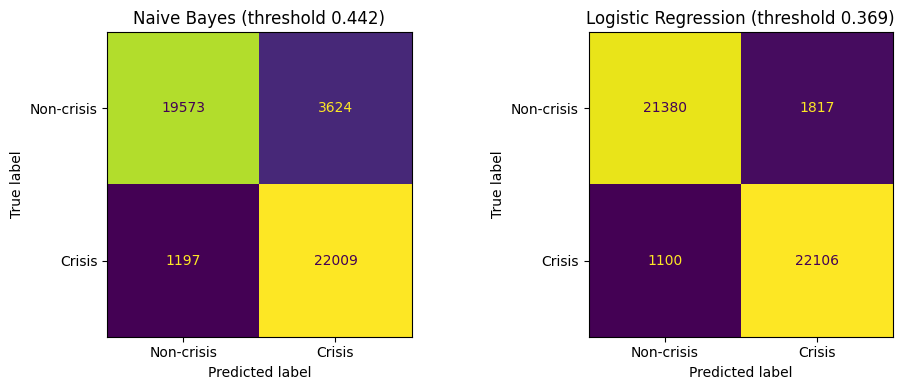

In [17]:
# cell 17
# confusion matrices

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

#two side by side panels
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

#pairs each panel with one model
for ax, (name, probs, key) in zip(axes, [("Naive Bayes", nb_test_probs, "naive_bayes"),("Logistic Regression", lr_test_probs, "logistic_regression")]):
    t = chosen_thresholds[key]
    #uses each models tuned threshold
    preds = (probs >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=["Non-crisis", "Crisis"],ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{name} (threshold {t:.3f})")

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/CS74/confusion_matrices.png", dpi=200)
plt.show()

           length  all posts  crisis posts  NB recall  LR recall
0     short (≤15)       4558           766      0.815      0.719
1  medium (16–80)      21656          6594      0.916      0.907
2      long (>80)      20189         15846      0.969      0.983


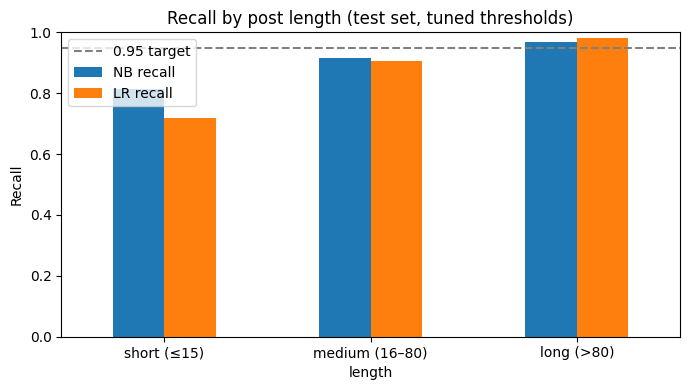

In [18]:
# cell 18
# length analysis - how does detection change with message length?

#sorts each test post into a length group by its word count
length_bins = pd.cut(X_test["word_count"], bins=[0, 15, 80, np.inf],labels=["short (≤15)", "medium (16–80)", "long (>80)"])
is_crisis = (y_test == 1).values

rows = []
for b in length_bins.cat.categories:
    in_bin = (length_bins == b).values
    crisis_in_bin = in_bin & is_crisis #keeps posts that are in this length group and are crisis posts
    row = {"length": b, "all posts": in_bin.sum(), "crisis posts": crisis_in_bin.sum()}
    for name, probs, key in [("NB", nb_test_probs, "naive_bayes"),("LR", lr_test_probs, "logistic_regression")]:
        preds = probs >= chosen_thresholds[key]
        #recalll for that group - share of crisis posts that got flagged
        row[f"{name} recall"] = preds[crisis_in_bin].mean()
    rows.append(row)

length_table = pd.DataFrame(rows).round(3)
length_table.to_csv("/content/drive/MyDrive/CS74/length_analysis.csv", index=False)
print(length_table)

ax = length_table.set_index("length")[["NB recall", "LR recall"]].plot(kind="bar", figsize=(7, 4), rot=0)
ax.axhline(0.95, linestyle="--", color="gray", label="0.95 target")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.set_title("Recall by post length (test set, tuned thresholds)")
ax.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/CS74/length_recall.png", dpi=200)
plt.show()

The 0.95 recall is sneaky. Long posts make up about 68% of crisis posts, and models do great. Based on the numbers, about 3/4 of the misses come from short and medium posts, even though these are less than a third of all crisis posts. LR wins on long posts, but NB wins on short posts. This matters a lot because messages to a mental health chat bot (my motivation) are usually shorter messages.

Recall declines substantially for short posts. LR caught 98% of long crisis posts but only 71% of short ones. NB caught 81.5% of short posts.